In [23]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('../../code')
from utils import simulate_single_server_queue_from_times
from tqdm import tqdm

<div dir="rtl">

## בשביל מה אנחנו כאן?

### בתור מהנדסי תעשייה אנחנו צריכים למצוא פתרונות יעילים למערכות מסובכות.

## למשל:

### מציאת כמות שרתים אופטמיאלית בcall center.

### לדעת כמה מוצרים להזמין למחסן בניהול מערכת מלאי

### לדעת לאן להוביל לקוחות בתור מערכת שירות גדולה.

### כיצד נדע לעשות את כל הדברים האלו?

## בשביל זה אנחנו צריכים קודם להגדיר פונקציית עלות - בתעשייה אוהבים לקרוא לזה: 

### KPI's: Key Performance Indicators

<div dir="rtl"> 

## דוגמא בתורים:

### נניח כי יש לנו מערכת תורים פשוטה שיש לו רק תור יחיד. 

### המערכת נקנסת על כל צרכן שמחכה יותר מ-6 דקות. עלות קנס על כל צרכן שנקנס היא 100 ש"ח. 

### איך מחשבים את העלות פה? 
### אולי לפני זה - נרצה לשאול, האם מחשבים עלות ליום? לחודש? לשנה? 

### נסמן ב$W_t$ מ"מ שמבטא את ההמתנה של צרכן במערכת. 

### מה הסיכוי שהוא יחכה יותר מ-6 דקות?

### זה שקול ל:

### $$ P(W_t > 6) $$ 

### מה תהיה העלות על הכוללת לצרכן בודד?

### $$ 100*P(W_t > 6) $$

### מה תהיה עלות כוללת ליחידת זמן?

### בעצם זה תלוי כמה צרכנים מגיעים למערכת כל יחידת זמן? אם כל דקה מגיעים 4 צרכנים ולכול אחד מהם הסתברות של $P(W_t>6)$ לקבל קנס  אז סה"כ מקבלים:

### $$ 4*P(W_t>6) $$

### קנסות כל יחידת זמן ולכן עלות כוללת ליחידת זמן היא:

### $$ 100*4*P(W_t>6) $$

<div dir="rtl"> 

## אז בשביל מה אנחנו עושים סימולציה?

### בשביל לחשב את העלות הכוללת אנחנו צריכים לדעת 3 דברים.

### 1. קצב הגעה - זה בד"כ נתון.
### 2. עלות קנס - זה בד"כ נתון.
### 3. הסתברות שהמתנה תהיה מעל 6 דקות - זה תלוי בתהליך סטוכסטי מסובך מאד שאין לו פתרון אנליטי. 

### הרעיון הכללי - מנסחים פונקציית עלות - מחפשים את המדד הסטוכסטי שאותו נשער דרך הסימולציה ונחשב אותו. 

<div dir="rtl"> 


## אז נניח שנרצה לחשב את ההסתברות שזמן המתנה יהיה יותר מ-6 יחידות זמן. 

### איך היינו עושים את זה אם היינו מדברים בשפה של סימולציה. 

### היינו בעצם שואלים מה פרופרוציות הפעמים שזמן ההמתנה היה מעל 6 יחידות זמן.

### נעשה דוגמא פשוטה: 

### נניח כי יש תור יחיד עם שרת יחיד.

### מה קובע את ההתפלגות זמן ההמתנה: 

#### 1. התפלגות בין הגעות.
#### 2. התפלגות זמן שירות.

### בעתיד נוכל לסבך את העניינים ונגיד כי השרת יוצא לפעמים לא עובד או שצרכנים נוטשים את התור לפעמים - אבל כרגע נשמור את זה פשוט. 

### ניקח דוגמא: התפגלות זמנים בין הגעות מפולג gamma(2,2)
### התפלגות זמן שירות מפולג מעריכי עם exp(1.25)

## מה זה אומר בעצם: 
### הgamma בעצם אומר שיש לנו סכום של שני מעריכים - כל אחד עם קצב 2. כלומר
### התוחלת שלו: 2/2 =1

### שירות יש לנו מערכי עם קצב 1.25 כלומר תוחלת 1/1.25 = 0.8

### נעשה סימולציה עם הנתונים האלה:

## כאשר משתמשים בnp.random הוא דווקא מקבל את התוחלת ולא את הקצב

In [9]:
inter_arrival_times = np.random.gamma(2,1/2,2500)
inter_arrival_times.mean()

np.float64(0.9969997987550759)

In [10]:
service_times = np.random.exponential(1/1.25, 2500)
service_times.mean()

np.float64(0.8076300777109312)

In [15]:
waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times,
    service_times=service_times,
)

print(f"P(waiting time > 6): {np.mean(waiting_times > 6):.4f}")

P(waiting time > 6): 0.0620


In [16]:
print(f"Queue length distribution: {queue_length_distribution}")
print(f"Number in system distribution: {number_in_system_distribution}")
print(f"Mean waiting time: {waiting_times.mean():.3f}")
print(f"Mean sojourn time: {sojourn_times.mean():.3f}")

Queue length distribution: [0.41712571 0.18543775 0.1265862  0.08503871 0.05688917 0.03992049
 0.02770282 0.01371819 0.01142501 0.01309386 0.00954824 0.00498672
 0.00395406 0.00392296 0.0006501 ]
Number in system distribution: [0.19080249 0.22632322 0.18543775 0.1265862  0.08503871 0.05688917
 0.03992049 0.02770282 0.01371819 0.01142501 0.01309386 0.00954824
 0.00498672 0.00395406 0.00392296 0.0006501 ]
Mean waiting time: 1.846
Mean sojourn time: 2.653


<div dir="rtl">

## בתורים נרצה לחשב 4 מדדים שמהם נגזר הכל:

### 1. התפלגות זמן המתנה - נסמן כ $W_q$
### 2. התפלגות זמן שהייה: נסמן כ$W$ כלומר זמן המתנה + זמן שירות
### 3. התפלגות אורך התור: נסמן כ$L_q$.
### 4. התפלגות מספר הצרכנים במערכת (תור + שירות) נסמן כ$L$

## סימולציה כאומד:

### זוכרים אי-שם בשנה ב שלמדתם סטטיסטיקה?

### לא זוכרים? אנחנו פה כדי לעורר זכרונות

## מהו אומד? 

### פונקציה של הנתונים שמשערכת ערך מסוים.

## למשל: ממוצע משערך תוחלת.

### או למשל, אם נתון לנו את הסדרה הבאה:

### $$ x_1, x_2, ...,x_n $$

### האומד לשונות הוא:

## $$ s^2 =  \frac{\sum_{i=1}^n (x_i- \bar{x})^2 }{n-1} $$

## אוקיי - זה לסטטיסטיקה אבל מה לנו ולזה?

### מה סימלוציה עושה? היא משערכת מדדים של תהליך סטוכסטי

### למשל: פרופורצית הפעמים שזמן המתנה גדולך מ-6 הוא האומד להסתברות שזמן המתנה גדול מ-6.

### מה יהיה האומד להסתברות שברגע אקראי יהיו 3 צרכנים במערכת: 

### ניחשתם נכון: פרופורציות הזמן שיש 3 צרכנים במערכת. 

### למשל: אם עשינו סימולציה ל100 יחידות זמן ו30.2 יחידות זמן יש 3 צרכנים במערכת אז נשער שההסתברות ל-3 צרכנים היא 0.302. 

<div dir="rtl">

    
#### מהו אמד טוב? למה לקחנו את ההממוצע כדי למדוד את התוחלת? למה לא המקסימום של המדגם? או המינימום?
    
#### במקרה של תוחלת ממוצע זה די מתבקש, אבל אם נרצה לאמוד שונות של אוכלוסייה? מה יהיה האמד אז? זה לא תמיד כלכך פשוט. 
    
    
### בשביל לדעת אם אומד הוא טוב, נרצה לחשב 2 קריטריונים שנרצה שהערך של שניהם יהיה נמוך.
    
## Bias או הטייה: 
    
$$ bias(\hat{\mu}, \mu) = E[\hat{\mu}]- \mu $$
    
### מה זה אומר המדד הזה? הכוונה היא שאם ניקח נשתמש במדד הזה  - בממוצע הוא היה פוגע בערך האמיתי. נדגים: 

$$ E[aX]=aE[X] $$

$$ E[X_1+X_2] = E[X_1]+E[X_2] $$

### $$ E[x_i] = \mu $$

### $$\hat{\mu}  = \bar{x} = \sum_{i=1}^n \frac{x_i}{n}$$

#### $$ E[\hat{\mu} ] = E[\sum_{i=1}^n \frac{x_i}{n}] $$
#### $$ = \frac{1}{n}E[x_1 +x_2+..+ x_n] =\frac{1}{n} (E[x_1]+E[x_2]+.. + E[x_n]) = \frac{1}{n}(n \mu) = \mu$$

In [17]:
np.random.rand(100000000).mean()

np.float64(0.5000135908578164)

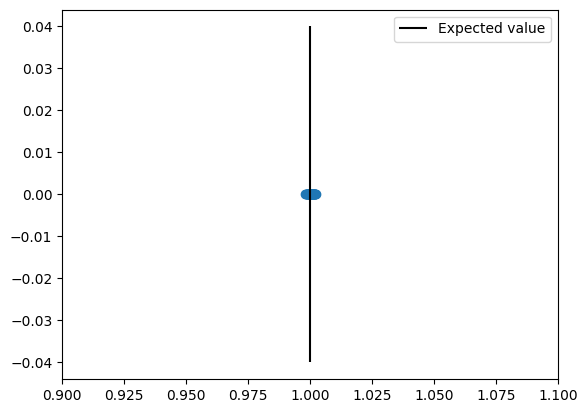

In [18]:
import matplotlib.pyplot as plt

samples = []
for ind in range(50):
    sample = np.random.uniform(0.8, 1.2, 10000)
    samples.append(sample.mean())
    

plt.figure()
plt.scatter(samples, np.zeros(50) )
plt.vlines(1, -0.04, 0.04, colors=None, linestyles='solid', label = 'Expected value', color = 'black')
plt.legend()
plt.xlim(0.9,1.1)
plt.show()

In [19]:
samples = []
for ind in range(500000):
    sample = np.random.uniform(0.8, 1.2, 10)
    samples.append(sample.mean())
    
np.array(samples).mean()

np.float64(1.000053251955732)

<div dir="rtl"> 

### אמד שהbias שלו הוא 0 נקרא אמד חסר הטיה. ידוע בקיצור אח"ה 
    
### חשוב לציין - אם נסמן את תוחלת האוכלוסייה ב$\mu$ אזי ש: $E[X_i]=\mu$
    

    
#### קריטריון אחר הוא השונות של האמד:
    
$$ Var[\hat{\mu}] $$
    
   
### חשוב לציין - אם נסמן את שונות האוכלוסייה ב$\sigma^2$ אזי ש: $Var[X_i]=\sigma^2$
   
   
#### בדוגמא לעיל נרצה לדעת מהו השונות של האמד $\bar{X}$. 
    
    
    
$$ Var[\bar{X}] = Var[\sum_{i=1}^n \frac{X_i}{n}] = \frac{1}{n^2}Var[X_1+X_2...+X_n] = \frac{1}{n^2}n \sigma^2 =  \frac{\sigma^2}{n} $$

## נראה שהשונות של האמד קטנה עם n. 
    
#### נדגים: 
    


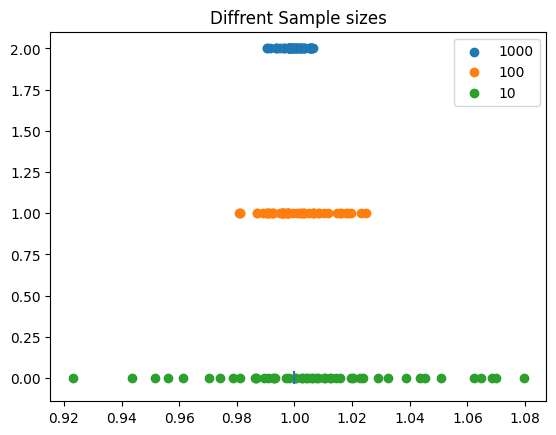

In [20]:
samples_10 = []
for ind in range(50):
    sample = np.random.uniform(0.8, 1.2, 10)
    samples_10.append(sample.mean())
    



samples_100 = []
for ind in range(50):
    sample = np.random.uniform(0.8, 1.2, 100)
    samples_100.append(sample.mean())
    


samples_1000 = []
for ind in range(50):
    sample = np.random.uniform(0.8, 1.2, 1000)
    samples_1000.append(sample.mean())
    
plt.figure()
plt.scatter(samples_1000, 2+ np.zeros(50), label = 1000 )
plt.scatter(samples_100, 1+ np.zeros(50), label = 100 )
plt.scatter(samples_10,  np.zeros(50), label = 10 )

plt.vlines(1, -0.04, 0.04, colors=None, linestyles='solid')
plt.title('Diffrent Sample sizes')
plt.legend()
plt.show()


<div dir="rtl">
    
### סיכום ביניים - כאשר אנחנו אומדים פרמטר של אוכלוסייה בעזרת אומד כלשהו נרצה שני דברים. שהאומד שלנו יהיה עם הטייה נמוכה, אידיאלית עם הטייה אפסית ושתהיה לו שונות מינימאלית.
    
### אם נרצה לחבר את שני חלקים אלו ניתן לעשות זאת על ידי מדד שנקרא MSE. נניח עבור פרמטר $\theta$
    
### $$ MSE(\hat{\theta}) = E[(\theta-\hat{\theta})^2] = Bias(\hat{\theta})^2 + Var(\hat{\theta})  $$
    
### למשל נשווה בין שני אומדים לשונות: 
    
### 1. $$ \hat{\sigma^2} = \sum_{i=1}^n \frac{(X_i-\bar{X})^2}{n} $$

### הbias שלו הוא 

###   $$  \frac{n+1}{n}\sigma^2 - \sigma^2  = \frac{1}{n}\sigma^2 $$ 

### 2. $$ \hat{\sigma^2} = \sum_{i=1}^n \frac{(X_i-\bar{X})^2}{n-1} $$
    
### הbias שלו הוא 0
    
### לא נראה את החישוב של השונות של שני האומדים האלו רק נציין שהשונות של האומד הראשון קטנה יותר ולמרות שהוא אומד מוטה הMSE שלו גם קטן יותר. 

<div dir="rtl">

## שונות של אומד

### אומד הוא משתנה מקרי.

### לכן יש לו שונות:

$$
\text{Var}(\hat\theta)
$$

### שונות קטנה פירושה אומד יציב ומדויק יותר.

### לדוגמה:

$$
\text{Var}(\bar X)=\frac{\sigma^2}{n}
$$



<div dir="rtl">

## אומד חסר הטיה

### אומד חסר הטיה מקיים:

$$
E(\hat\theta)=\theta
$$

### כלומר, בממוצע הוא פוגע בערך האמיתי.

### דוגמה:

$$
E(\bar X)=\mu
$$

### לכן ממוצע המדגם הוא אומד חסר הטיה לתוחלת.



</div>

<div dir="rtl"> 

### בקורס הזה נתעסק רק עם אומדים חסרי הטיה. 

### נרצה להקטין את השונות כמה שיותר. בשביל להקטין את השונות נרצה להריץ את הסימולציה כמה שיותר

# בדיקת שונות של אומד:

## בשביל זה צריך לעשות את אותה סימולציה כמה פעמים ונראה מה היה הערך החזוי כל פעם וכמה הערכים משתנים אחד מהשני.

In [36]:
num_samples = 10

waiting_times_dict = {}
for n in [2500, 50000,500000]:
    waiting_times_dict[n] = []

for n in [2500, 50000,500000]:
    for ind in tqdm(range(num_samples)):    
        inter_arrival_times = np.random.gamma(2,1/2,n)
        service_times = np.random.exponential(1/1.25, n)
        waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times,
    service_times=service_times,
)
        waiting_times_dict[n].append(waiting_times.mean())

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [02:14<00:00, 13.45s/it]


In [37]:
waiting_times_dict[2500]

[np.float64(1.662682205964918),
 np.float64(3.0022466348054384),
 np.float64(2.4102471673961174),
 np.float64(2.700488006654577),
 np.float64(2.8046965800144945),
 np.float64(2.354273256607692),
 np.float64(1.867220867991418),
 np.float64(2.5662846945551325),
 np.float64(2.358248913644013),
 np.float64(2.0263465074233906)]

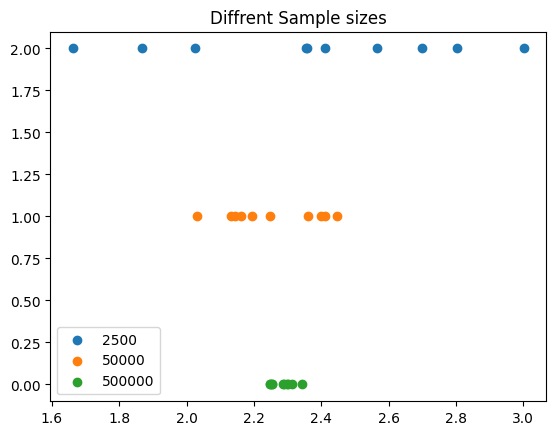

In [38]:
n1 = 2500
n2 = 50000
n3 = 500000
plt.figure()

plt.scatter(waiting_times_dict[n1], 2 + np.zeros(num_samples), label = n1 )
plt.scatter(waiting_times_dict[n2], 1+ np.zeros(num_samples), label = n2 )
plt.scatter(waiting_times_dict[n3],  np.zeros(num_samples), label = n3 )

plt.title('Diffrent Sample sizes')
plt.legend()
plt.show()

<div dir="rtl">

## כלומר סימולציה יותר ארוכה - פירושה אמד מדויק יותר

### אבל הבעיה היא שזה מגיע עם עלות של זמן ריצה. 

### במקרה פה זמני הריצה היו:

### 1. עבור 2500 הגעות: זמן ריצה היה פחות משנייה עבור 10 סימולציות.
### 2. עבור 50000 הגעות: זמן ריצה היה  13 שניות עבור 10 סימולציות.
### 3. עבור 50000 הגעות: זמן ריצה היה  2 דקות ו14 שניות  עבור 10 סימולציות.


<div dir="rtl">

## קביעת אורך סימולציה

### אין אמת מוחלטת כמה זמן סימולציה נריץ.

### דרך מקובלת לעשות את זה על ידי חישוב ר"ס ולהכריע מהו יהיה אורך ר"ס הכי ארוך שנהיה מוכנים לקבל.

### נחשב ר"ס עבור על אחד מהגדלים הללו:



In [39]:
waiting_times_dict[n1]

[np.float64(1.662682205964918),
 np.float64(3.0022466348054384),
 np.float64(2.4102471673961174),
 np.float64(2.700488006654577),
 np.float64(2.8046965800144945),
 np.float64(2.354273256607692),
 np.float64(1.867220867991418),
 np.float64(2.5662846945551325),
 np.float64(2.358248913644013),
 np.float64(2.0263465074233906)]

In [40]:
import numpy as np
from scipy import stats

for n in [2500, 50000, 500000]:
    
    x = waiting_times_dict[n]
    confidence = 0.95
    n = len(x)
    se = stats.sem(x)  # standard error
    t_crit = stats.t.ppf((1 + confidence) / 2, n - 1)
    
    ci_length = 2 * t_crit * se
    print('The CI lenght for n = {} is {}' .format(n, ci_length))

The CI lenght for n = 10 is 0.6050032792021116
The CI lenght for n = 10 is 0.20426390386847945
The CI lenght for n = 10 is 0.045514290637554335


<div dir="rtl">

### ניתן לראות שככל שהסימולציה ארוכה יותר הר"ס קטן יותר- שזה מה שנרצה שיקרה. 

## קצת על סימונים: אם אנחנו מנתחים תור יחיד עם שרת יחיד כאשר תהליך ההגעה והשירות אינם מרקובים נסמן את התור הזה כ:

### $$ GI/GI/1 $$

## במקרה הכללי: נקרא סימון Kendall

### $$  A/S/c $$

### $A$ מתאר תהליך הגעה. 
### $S$ מתאר תהליך הגעה. 

## לרוב נסמן אותם אחד מ-3 אפשריות:

### 1. $M$ תהליך מרקובי כלומר מפולג מעריכי
### 2. $GI$ תהליך כללי כאשר הI מתאר שאין תלות בין הגעות\שירותים
### 3. $G$ תהליך כללי אך עם קורלציות. נרחיב על כך בהמשך.

### ה-c מתאר את כמות השרתים.
### במקרה כזה נניח כי השרתיםפ הומוגנים כלומר לכולם יש אותו התפלגות שירות.

### אם יש להניח שהשרתים אינם הומוגנים אזי  הסימון נראה כך:

### $$ GI/GI_i/c $$
